# <b> <font color='#A20025'> Appendix I &middot; Notebook 2 of 5: Flow Matching: Straight-Line Generative Modeling</font> </b>

*This is a bonus notebook accompanying Appendix I of [Build AI Drug Discovery Pipelines](https://github.com/nrflynn2/ml-drug-discovery). It is self-contained and runnable end to end; read it side by side with the appendix. This notebook builds a conditional flow matcher on the same two-moons target and shows why it needs far fewer sampling steps.*

In Notebook 1 you built a diffusion model and hit its wall: **sampling needs many reverse steps**, and quality collapses when you cut them. This notebook introduces the method that fixes that; **flow matching (FM)**; and you will feel the difference on the *exact same* two-moons target.

The mental model shift is worth stating up front:

- **Diffusion** learns to *reverse a stochastic noising process*, one small denoising step at a time.
- **Flow matching** learns a **velocity field**; an arrow at every point in space telling a sample which way to move; and generates by **following those arrows** along a smooth path from noise to data. Sampling becomes solving an **ordinary differential equation (ODE)**.

Because the learned path can be made almost *straight*, an ODE solver can traverse it in a handful of steps. That is the whole pitch, and by the end of this notebook you will have:
- Trained a velocity field with **conditional flow matching** using the `torchcfm` library, on the same MLP architecture as Notebook 1.
- Generated samples by **integrating an ODE** with a simple Euler solver you can read in five lines.
- Seen FM produce clean moons in as few as **4-8 steps**; where diffusion needed dozens.
- Decomposed that advantage with a **controlled three-sampler sweep**, separating what the method buys from what the sampler buys.

> Flow matching **generalizes** diffusion: with particular choices of its noise schedule, the FM objective recovers diffusion-style paths (Lipman et al., 2023). You are learning the more general tool.

## <b> <font color='#A20025'> Environment Setup</font> </b>

Run once. On **Colab**, this installs `torchcfm` (the conditional-flow-matching library) and `POT` (for the distribution-distance metric), which are not preinstalled; PyTorch and the scientific stack already are. Locally it is a no-op if present.

In [5]:
# --- Colab-friendly setup: safe to re-run ---
import importlib, subprocess, sys
def _ensure(pkg, import_name=None):
    try:
        importlib.import_module(import_name or pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
for pkg, name in [("torchcfm", "torchcfm"), ("scikit-learn", "sklearn"),
                  ("POT", "ot"), ("matplotlib", "matplotlib")]:
    _ensure(pkg, name)

import os
os.environ.setdefault("OMP_NUM_THREADS", "4")
os.environ.setdefault("MKL_NUM_THREADS", "4")
print("Setup complete; CPU-only, no GPU required.")

Setup complete; CPU-only, no GPU required.


### <b> <font color='#A20025'> Import Packages</font> </b>

In [7]:
import math, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from torchcfm.conditional_flow_matching import ConditionalFlowMatcher

torch.set_num_threads(4)
torch.manual_seed(0); np.random.seed(0)
print("torch", torch.__version__, "| torchcfm ConditionalFlowMatcher ready | CUDA:", torch.cuda.is_available())

torch 2.13.0+cu130 | torchcfm ConditionalFlowMatcher ready | CUDA: False


### <b> <font color='#A20025'> Where this notebook's data lives</font> </b>

This notebook trains its own toy in about a minute, but the quantitative sweep later on is
heavier: four samplers times ten step budgets times five seeds, with a 2000-by-2000 distance
matrix behind every point. We ran it once and committed the results, so you can read the numbers
instantly and still reproduce them on demand. The cell below resolves paths relative to the
notebook's own folder, which is what makes the same code work whether you are on Colab or a local
clone, and defines the CSV reader those loads use.

That reader deserves a sentence of its own, because it encodes a bug worth avoiding. Our CSVs
begin with commented provenance lines, and the natural way to skip them is `pd.read_csv(...,
comment='#')`. That works here but is a trap in general: `#` is also the SMILES notation for a
triple bond, so `comment='#'` truncates any molecule containing one, mid-row, **without raising**.
In the companion novelty file for Notebook 4 it silently blanks 2 of 20 molecules. Strip the
header yourself and hand pandas a clean buffer; the habit costs four lines and saves a
debugging afternoon.

In [10]:
# --- Path setup: resolve data relative to this notebook, so paths work on Colab and locally ---
from pathlib import Path
import os

# On Colab, clone the repo and move into this notebook's folder on first run.
if not Path("data").exists() and not Path("../data").exists():
    if os.path.exists("/content"):  # Colab
        os.system("git clone --depth 1 https://github.com/nrflynn2/ml-drug-discovery.git")
        os.chdir("ml-drug-discovery/Appendix_I_FLYNN_ML4DD/notebooks")

HERE = Path.cwd()
APPENDIX = HERE.parent if HERE.name == "notebooks" else HERE
DATA = APPENDIX / "data"
FIGURES = APPENDIX / "figures"
ARTIFACTS = APPENDIX / "artifacts"
ARTIFACTS.mkdir(exist_ok=True)


def load_csv_with_provenance(path, fallback=None):
    """Read one of the appendix CSVs, skipping any leading '#' provenance header.

    Do NOT reach for pandas' comment='#' here. These files carry commented provenance
    lines at the top, but '#' is also the SMILES symbol for a triple bond, so
    comment='#' would silently truncate any row containing one (in the companion
    novelty CSV it blanks 2 of 20 molecules with no error). Strip the header
    explicitly, then hand pandas a clean buffer.
    """
    import io
    p = Path(path)
    if not p.exists() and fallback is not None:
        p = Path(fallback)
    lines = p.read_text().splitlines()
    i = 0
    while i < len(lines) and lines[i].lstrip().startswith("#"):
        i += 1
    return pd.read_csv(io.StringIO("\n".join(lines[i:])))


# Print a repo-relative path so the notebook reads the same on Colab and locally.
print("appendix folder:", APPENDIX.name, "| data dir:", DATA.relative_to(APPENDIX.parent)
      if APPENDIX.parent in DATA.parents else DATA.name)

appendix folder: Appendix_I_FLYNN_ML4DD | data dir: Appendix_I_FLYNN_ML4DD/data


## <b> <font color='#A20025'> The same target as Notebook 1</font> </b>

To make the comparison fair, flow matching must aim at the *identical* distribution diffusion did:

- **Source** $x_0 \sim \mathcal{N}(0, I)$; standard 2-D Gaussian.
- **Target** $x_1$; scikit-learn's two half-moons, standardized (mean 0, unit variance) with the *same* fixed constants as Notebook 1.

One notation note that trips people up: in flow matching the convention is **time $t$ runs from 0 to 1**, with $t=0$ at the **source (noise)** and $t=1$ at the **target (data)**; the opposite direction from the diffusion timestep index. Keep that in mind and everything lines up.

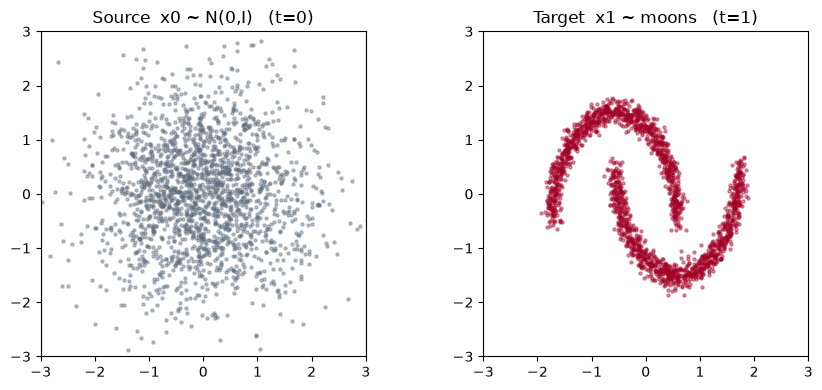

In [13]:
# ---- SHARED TARGET (identical constants to Notebook 1) ----
_Xref, _ = make_moons(n_samples=100_000, noise=0.06, random_state=0)
MOON_MEAN = _Xref.mean(0).astype(np.float32)
MOON_STD  = _Xref.std(0).astype(np.float32)

def sample_target(n, seed=None):
    """x1 ~ target: two standardized half-moons."""
    X, _ = make_moons(n_samples=n, noise=0.06, random_state=seed)
    return ((X.astype(np.float32) - MOON_MEAN) / MOON_STD)

def sample_source(n, generator=None):
    """x0 ~ source: standard normal N(0, I)."""
    return torch.randn(n, 2, generator=generator)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
src = sample_source(2000).numpy(); tgt = sample_target(2000, seed=1)
for ax, data, title, c in [(axes[0], src, "Source  x0 ~ N(0,I)   (t=0)", "#5B6B7B"),
                           (axes[1], tgt, "Target  x1 ~ moons   (t=1)", "#A20025")]:
    ax.scatter(data[:, 0], data[:, 1], s=5, alpha=0.4, color=c)
    ax.set_title(title); ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_aspect("equal")
fig.tight_layout(); plt.show()

## <b> <font color='#A20025'> The idea: learn a velocity field, then follow it</font> </b>

Imagine every sample as a particle. At $t=0$ it sits somewhere in the Gaussian cloud; by $t=1$ you want it to have drifted onto a moon. **Flow matching learns the velocity of that drift**; a function $v_\theta(x, t)$ that returns, for any position $x$ and time $t$, the arrow the particle should follow.

The elegant part is how you get a training target *without* knowing the true global velocity. **Conditional** flow matching picks a source point $x_0$ and a target point $x_1$, draws the **straight line** between them, and declares the velocity along that line to be simply their difference:

$$x_t = (1-t)\,x_0 + t\,x_1, \qquad u_t = x_1 - x_0$$

Then it trains the network to match that conditional velocity, averaged over many random $(x_0, x_1)$ pairs and times $t$:

$$\mathcal{L}(\theta) = \mathbb{E}_{t,\,x_0,\,x_1}\;\big\lVert\, v_\theta(x_t, t) - (x_1 - x_0)\,\big\rVert^2$$

Individually each pair points along a naive straight line; **averaged over the data**, the learned field $v_\theta$ becomes a smooth flow that transports the *whole* Gaussian onto the *whole* moons distribution. That averaging is the magic; and it is why the marginal paths end up nearly straight, which is exactly what lets an ODE solver take big steps.

You will let `torchcfm` handle the bookkeeping: its `ConditionalFlowMatcher` returns $(t, x_t, u_t)$ given a batch of source and target points. Your only job is to regress $v_\theta(x_t, t)$ onto $u_t$.

In [16]:
# Same architecture as Notebook 1; but now the MLP outputs a VELOCITY, not a noise estimate.
class SinTimeEmb(nn.Module):
    def __init__(self, dim=64):
        super().__init__(); self.dim = dim
    def forward(self, t):
        half = self.dim // 2
        freqs = torch.exp(-math.log(10000.0) * torch.arange(half) / (half - 1))
        a = t[:, None] * freqs[None] * 2 * math.pi
        return torch.cat([torch.sin(a), torch.cos(a)], dim=-1)

class FieldMLP(nn.Module):
    def __init__(self, data_dim=2, hidden=128, temb=64, depth=3):
        super().__init__()
        self.temb  = SinTimeEmb(temb)
        self.tproj = nn.Sequential(nn.Linear(temb, hidden), nn.SiLU(), nn.Linear(hidden, hidden))
        layers = [nn.Linear(data_dim + hidden, hidden), nn.SiLU()]
        for _ in range(depth - 1):
            layers += [nn.Linear(hidden, hidden), nn.SiLU()]
        layers += [nn.Linear(hidden, data_dim)]
        self.net = nn.Sequential(*layers)
    def forward(self, x, t):
        return self.net(torch.cat([x, self.tproj(self.temb(t))], dim=-1))

vfield = FieldMLP()
print("Velocity-field parameters:", sum(p.numel() for p in vfield.parameters()),
      "(same as the NB1 denoiser)")

Velocity-field parameters: 74882 (same as the NB1 denoiser)


## <b> <font color='#A20025'> Train the velocity field with TorchCFM</font> </b>

Training mirrors Notebook 1's simplicity; one MSE loss, no adversary; but the recipe now pairs *source* and *target* points:

1. Draw a batch of targets $x_1$ (moons) and an equal batch of sources $x_0$ (Gaussian).
2. Hand them to `ConditionalFlowMatcher.sample_location_and_conditional_flow`, which samples a time $t$, the interpolated point $x_t$, and the conditional velocity $u_t = x_1 - x_0$.
3. Regress $v_\theta(x_t, t)$ onto $u_t$ with mean-squared error.

The `sigma` hyperparameter adds a little Gaussian width around the interpolation path (a small value keeps paths crisp). Same ~4000 steps, same ~minute on CPU.

> `torchcfm` is the reference implementation accompanying Tong et al. (2024), *Improving and Generalizing Flow-Based Generative Models with Minibatch Optimal Transport*. The plain `ConditionalFlowMatcher` you use here is the Lipman-style independent-coupling matcher; the library also offers an optimal-transport variant that straightens paths even further.

  step 1000/4000   loss 1.4450
  step 2000/4000   loss 1.4181
  step 3000/4000   loss 1.3938
  step 4000/4000   loss 1.3923
Trained in 47.8s


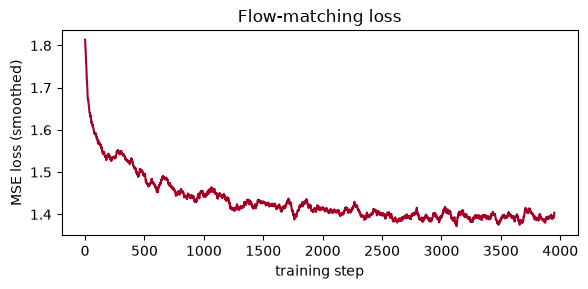

In [19]:
FM = ConditionalFlowMatcher(sigma=0.01)   # small sigma -> crisp, nearly-straight paths

def train_fm(steps=4000, bs=512, lr=2e-3, seed=0):
    torch.manual_seed(seed)
    net = FieldMLP()
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    hist = []; t0 = time.time()
    for it in range(steps):
        x1 = torch.from_numpy(sample_target(bs))     # target (data)
        x0 = torch.randn(bs, 2)                       # source (noise)
        # torchcfm returns: t (times), xt (interpolated point), ut (target velocity = x1 - x0)
        t, xt, ut = FM.sample_location_and_conditional_flow(x0, x1)
        vt = net(xt, t)
        loss = ((vt - ut) ** 2).mean()
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        hist.append(loss.item())
        if (it + 1) % 1000 == 0:
            print(f"  step {it+1:>4}/{steps}   loss {np.mean(hist[-200:]):.4f}")
    print(f"Trained in {time.time()-t0:.1f}s")
    return net, hist

vfield, hist = train_fm()

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(np.convolve(hist, np.ones(50)/50, mode="valid"), color="#A20025")
ax.set_xlabel("training step"); ax.set_ylabel("MSE loss (smoothed)")
ax.set_title("Flow-matching loss"); fig.tight_layout(); plt.show()

## <b> <font color='#A20025'> Sampling = integrating an ODE</font> </b>

To generate, you drop a particle at a noise sample $x(0)\sim\mathcal{N}(0,I)$ and **follow the learned velocity** forward in time to $x(1)$. Formally you solve the ODE

$$\frac{dx}{dt} = v_\theta(x, t), \qquad x(0)\sim\mathcal{N}(0, I),\; t: 0 \to 1.$$

The simplest solver is **forward Euler**: take $K$ equal steps of size $\Delta t = 1/K$, and at each one nudge the point by $\Delta t \cdot v_\theta$. That is the entire sampler; five lines, no stochasticity, no schedule:

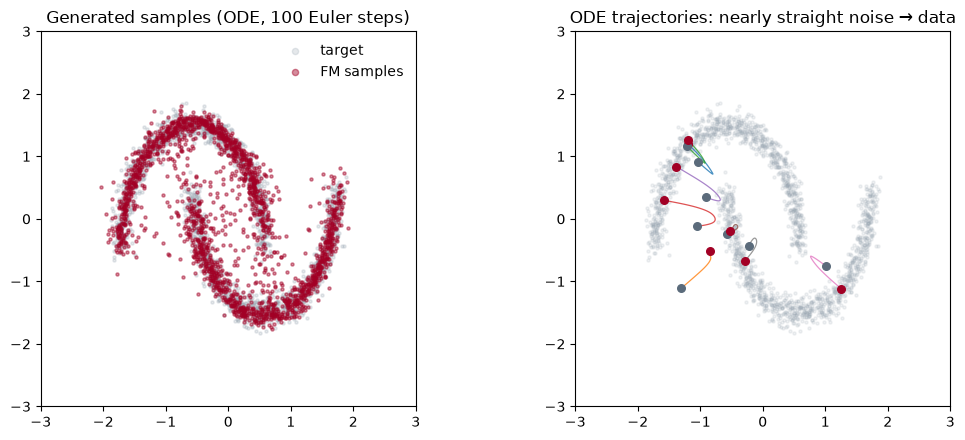

In [22]:
@torch.no_grad()
def fm_sample(net, n, steps, seed=0, record=False):
    """Integrate dx/dt = v(x, t) from t=0 (noise) to t=1 (data) with forward Euler."""
    g = torch.Generator().manual_seed(seed)
    x = torch.randn(n, 2, generator=g)
    dt = 1.0 / steps
    traj = [x.clone()]
    for i in range(steps):
        t = torch.full((n,), i * dt)
        x = x + dt * net(x, t)          # <-- one Euler step
        if record: traj.append(x.clone())
    return (x, traj) if record else x

gen = fm_sample(vfield, 2000, steps=100, seed=1).numpy()
tgt = sample_target(2000, seed=99)
_, traj = fm_sample(vfield, 8, steps=100, seed=2, record=True)
traj = torch.stack(traj).numpy()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(tgt[:, 0], tgt[:, 1], s=5, alpha=0.25, color="#9aa7b3", label="target")
axes[0].scatter(gen[:, 0], gen[:, 1], s=5, alpha=0.45, color="#A20025", label="FM samples")
axes[0].set_title("Generated samples (ODE, 100 Euler steps)")
axes[0].legend(frameon=False, markerscale=2); axes[0].set_aspect("equal")
axes[0].set_xlim(-3, 3); axes[0].set_ylim(-3, 3)
axes[1].scatter(tgt[:, 0], tgt[:, 1], s=5, alpha=0.15, color="#9aa7b3")
for k in range(traj.shape[1]):
    axes[1].plot(traj[:, k, 0], traj[:, k, 1], lw=0.9, alpha=0.8)
    axes[1].scatter(traj[0, k, 0], traj[0, k, 1], s=30, color="#5B6B7B", zorder=3)
    axes[1].scatter(traj[-1, k, 0], traj[-1, k, 1], s=30, color="#A20025", zorder=3)
axes[1].set_title("ODE trajectories: nearly straight noise → data")
axes[1].set_aspect("equal"); axes[1].set_xlim(-3, 3); axes[1].set_ylim(-3, 3)
fig.tight_layout(); plt.show()

Compare those **trajectories** to the diffusion ones in Notebook 1. The diffusion paths jitter; they are a noisy random walk. The flow-matching paths are **smooth and almost straight**, gliding from the Gaussian cloud onto the moons. Straight paths are easy to integrate with big steps, which is precisely why FM can sample in so few of them.

## <b> <font color='#A20025'> The payoff: crisp samples in very few steps</font> </b>

Here is the moment that motivates the whole chapter. Take the *same* trained velocity field and sample with shrinking step budgets; 100 all the way down to **just 4 Euler steps**. Where diffusion disintegrated below ~16 steps (Notebook 1), flow matching stays coherent far longer.

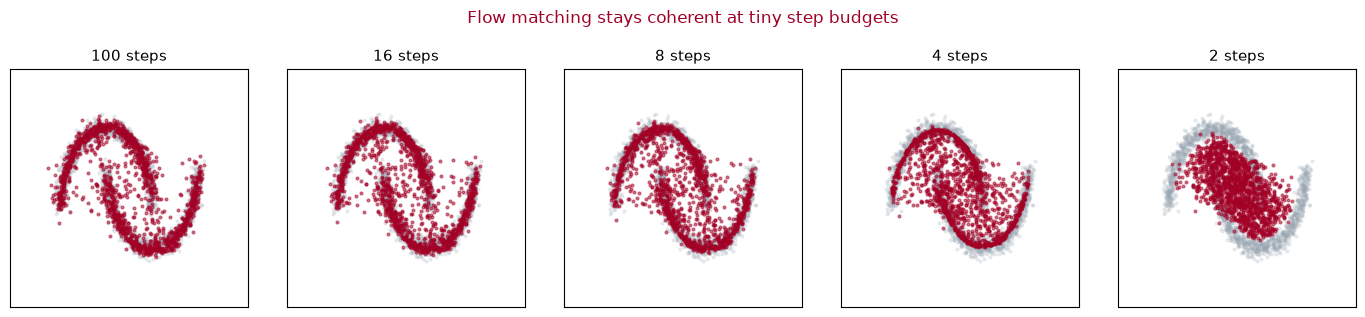

In [26]:
budgets = [100, 16, 8, 4, 2]
fig, axes = plt.subplots(1, len(budgets), figsize=(14, 3))
for ax, K in zip(axes, budgets):
    s = fm_sample(vfield, 1500, steps=K, seed=1).numpy()
    ax.scatter(tgt[:, 0], tgt[:, 1], s=4, alpha=0.18, color="#9aa7b3")
    ax.scatter(s[:, 0], s[:, 1], s=4, alpha=0.5, color="#A20025")
    ax.set_title(f"{K} steps", fontsize=11); ax.set_aspect("equal")
    ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Flow matching stays coherent at tiny step budgets", y=1.04, color="#A20025")
fig.tight_layout(); plt.show()

## <b> <font color='#A20025'> Was it the path, or was it the noise? A controlled decomposition</font> </b>

The claim you just watched happen qualitatively is that flow matching needs fewer steps. Before
banking it, it deserves a harder look, because the comparison as set up so far moves **two
variables at once**.

Think of it as a drug trial with a confounded control arm. Flow matching sampled by
**deterministic** Euler integration of an ODE. The Notebook 1 diffusion baseline sampled by the
**stochastic** ancestral walk, which injects fresh Gaussian noise at every step. So when flow
matching wins, two explanations fit equally well. Either the *paths* are genuinely straighter and
easier for a solver to traverse in a few big steps, which is the mechanism the method claims; or
we simply handed diffusion the clumsier of two available samplers and it lost a race it never
entered fairly. On that second reading the fourfold saving is an artifact of the experimental
design, and it would evaporate the moment somebody re-ran diffusion with a deterministic sampler.

That is a fair objection and it has a clean answer, because Notebook 1 gave you the missing arm.
DDIM at `eta=0` is the deterministic path for the **same trained network**, the same cosine
schedule, and the same respaced timesteps; the `eta=1` identity check proved the respacing is
shared, so `eta` is genuinely the only variable that moves. Adding that arm turns a confounded
two-way comparison into a controlled three-way one, and lets us split the advantage into two parts
we can measure separately:

- a **sampling-noise** component, the part that comes from the diffusion baseline being stochastic; and
- a **path-geometry** component, the part that comes from flow matching's straighter trajectories.

Run the sweep, then read the split off the numbers.

Notebook 2 is self-contained, so to run the comparison here we need the diffusion side present in
this kernel: the cosine noise schedule, the ancestral sampler, and the DDIM sampler, exactly as
Notebook 1 built them. The cell below brings all three over unchanged and loads both trained
networks from pinned checkpoints.

Pinning the checkpoints is deliberate and worth one sentence, because it fixes a real
reproducibility problem. Training on a multi-threaded CPU is not bit-deterministic, so two runs of
the same script give slightly different networks; the earlier version of this sweep trained its
diffusion network inline, and re-running it gave a materially different 8-step score. Loading fixed
weights makes every number below stable across machines and reruns. It also means the sweep
measures the *samplers*, holding the network constant, which is the whole point of the exercise.

In [30]:
# The diffusion side, brought over from Notebook 1 unchanged.
def cosine_betas(T, s=0.008):
    """Cosine noise schedule (Nichol & Dhariwal, 2021), as PER-STEP betas."""
    steps = torch.arange(T + 1, dtype=torch.float64)
    f = torch.cos(((steps / T) + s) / (1 + s) * math.pi / 2) ** 2
    abar_curve = f / f[0]
    betas = 1 - (abar_curve[1:] / abar_curve[:-1])
    return betas.clamp(1e-8, 0.999).float()

T     = 200
betas = cosine_betas(T)
abar  = torch.cumprod(1 - betas, 0)


def respace(steps):
    """The shared timestep subsequence. Both diffusion samplers use exactly this."""
    idx     = torch.linspace(0, T - 1, steps).round().long()
    ab_sub  = abar[idx]
    ab_prev = torch.cat([torch.ones(1, dtype=abar.dtype), ab_sub[:-1]])
    return idx, ab_sub, ab_prev


@torch.no_grad()
def ddpm_sample(net, n, steps=T, seed=0, record=False):
    """Ancestral (stochastic) reverse process, respaced to `steps` iterations."""
    g = torch.Generator().manual_seed(seed)
    idx, ab_sub, ab_prev = respace(steps)
    a_sub = ab_sub / ab_prev; b_sub = 1 - a_sub
    x = torch.randn(n, 2, generator=g, dtype=abar.dtype); traj = [x.clone()]
    for i in reversed(range(steps)):
        eps = net(x, torch.full((n,), idx[i]).to(abar.dtype) / T)
        ab, a, b = ab_sub[i], a_sub[i], b_sub[i]
        mean = (x - b / (1 - ab).sqrt() * eps) / a.sqrt()
        if i > 0:
            var = b * (1 - ab_prev[i]) / (1 - ab)
            x = mean + var.sqrt() * torch.randn(n, 2, generator=g, dtype=abar.dtype)
        else:
            x = mean
        if record: traj.append(x.clone())
    return (x, traj) if record else x


@torch.no_grad()
def ddim_sample(net, n, steps, eta=0.0, seed=0, record=False, x0_clip=None):
    """DDIM on the SAME ladder. eta=0 is deterministic; eta=1 recovers ddpm_sample."""
    g = torch.Generator().manual_seed(seed)
    idx, ab_sub, ab_prev = respace(steps)
    x = torch.randn(n, 2, generator=g, dtype=abar.dtype); traj = [x.clone()]
    for i in reversed(range(steps)):
        eps = net(x, torch.full((n,), idx[i]).to(abar.dtype) / T)
        ab, abp = ab_sub[i], ab_prev[i]
        x0 = (x - (1 - ab).sqrt() * eps) / ab.sqrt()
        if x0_clip is not None:
            x0 = x0.clamp(-x0_clip, x0_clip)
        if i > 0:
            sig2 = (eta ** 2) * (1 - ab / abp) * (1 - abp) / (1 - ab)
            c    = (1 - abp - sig2).clamp_min(0.0).sqrt()
            x = abp.sqrt() * x0 + c * eps + sig2.sqrt() * torch.randn(n, 2, generator=g, dtype=abar.dtype)
        else:
            x = abp.sqrt() * x0 + (1 - abp).clamp_min(0.0).sqrt() * eps
        if record: traj.append(x.clone())
    return (x, traj) if record else x


# Both pinned networks. Committed under data/; fetched on demand if you are running
# outside a clone of the repo.
import urllib.request

def load_pinned(fname):
    dest = DATA / fname
    if not dest.exists():
        dest = ARTIFACTS / fname
        if not dest.exists():
            urllib.request.urlretrieve(
                "https://raw.githubusercontent.com/nrflynn2/ml-drug-discovery/main/"
                "Appendix_I_FLYNN_ML4DD/data/" + fname, dest)
    net = FieldMLP()
    net.load_state_dict(torch.load(dest, map_location="cpu", weights_only=False)["model_state"])
    net.eval()
    return net

fm_net   = load_pinned("toy_fm_trained.pt")     # velocity field, this notebook's method
ddpm_net = load_pinned("toy_ddpm_trained.pt")   # noise predictor, the Notebook 1 baseline
print("both networks loaded |", sum(p.numel() for p in ddpm_net.parameters()), "parameters each")
print(f"terminal alpha_bar on this ladder: {abar[-1]:.3e}")

both networks loaded | 74882 parameters each
terminal alpha_bar on this ladder: 6.072e-08


In [31]:
# The three-sampler step-count sweep. USE_CACHED = True reads the committed results
# (instant); set it False to recompute from the cached networks (about three minutes on CPU).
USE_CACHED = True

BUDGETS = [1, 2, 4, 8, 16, 32, 64, 128, 200, 256]
SEEDS   = [0, 1, 2, 3, 4]
N_EVAL  = 2000
BAND    = 0.01          # the quality bar: energy distance to the target

from scipy.spatial.distance import cdist

def energy_distance(X, Y):
    """Energy distance between two point clouds: 2*E|X-Y| - E|X-X'| - E|Y-Y'|.

    Zero only when the two distributions match, and unlike a per-point error it is
    sensitive to shape and spread rather than to the pairing of individual samples.
    """
    X = np.asarray(X, np.float64); Y = np.asarray(Y, np.float64)
    return float(2 * cdist(X, Y).mean() - cdist(X, X).mean() - cdist(Y, Y).mean())

if USE_CACHED:
    sweep = load_csv_with_provenance(DATA / "toy_sampler_sweep.csv", "toy_sampler_sweep.csv")
    print(f"loaded {len(sweep)} rows from the committed sweep")
else:
    # fm_net and ddpm_net were loaded from pinned checkpoints in the cell above, not
    # retrained, so these numbers cannot drift between runs (multi-threaded CPU training
    # is not bit-deterministic).
    rows = []
    for steps in BUDGETS:
        for seed in SEEDS:
            ref = sample_target(N_EVAL, seed=1000 + seed)
            for name, draw in [
                ("fm_euler",         lambda: fm_sample(fm_net, N_EVAL, steps=steps, seed=seed)),
                ("ddpm_ancestral",   lambda: ddpm_sample(ddpm_net, N_EVAL, steps=steps, seed=seed)),
                ("ddim_eta0",        lambda: ddim_sample(ddpm_net, N_EVAL, steps=steps, seed=seed, eta=0.0)),
                ("ddim_eta0_x0clip", lambda: ddim_sample(ddpm_net, N_EVAL, steps=steps, seed=seed,
                                                         eta=0.0, x0_clip=4.0)),
            ]:
                t0 = time.time(); s = draw().numpy()
                rows.append(dict(sampler=name, steps=steps, seed=seed,
                                 energy_distance=energy_distance(s, ref),
                                 n_samples=N_EVAL, wall_clock_s=round(time.time() - t0, 4)))
        print(f"  budget {steps:>3} done")
    sweep = pd.DataFrame(rows)

mean_energy = sweep.groupby(["sampler", "steps"]).energy_distance.mean().unstack()


def crossing(sampler, band=BAND):
    """Smallest budget > 1 whose seed-mean energy is under the band and stays under it.

    steps=1 is excluded: for the respaced diffusion samplers it is a degenerate no-op
    (see the discussion below), so its score is a property of the input noise, not of
    the sampler.
    """
    s = mean_energy.loc[sampler].dropna()
    s = s[s.index > 1]
    for k in s.index:
        if s.loc[k] < band and (s.loc[s.index >= k] < band).all():
            return int(k)
    return None

print("\nmean energy distance to target (5 seeds, 2000 samples)\n")
print(mean_energy.round(5).to_string())
print("\ncrossing budget for the %.2f band:" % BAND)
for s in ["fm_euler", "ddpm_ancestral", "ddim_eta0", "ddim_eta0_x0clip"]:
    c = crossing(s)
    if c is not None:
        print(f"  {s:18s} {c}")
    else:
        row = mean_energy.loc[s].dropna()
        row = row[row.index > 1]          # exclude the degenerate 1-step no-op, as crossing() does
        best_k = int(row.idxmin())
        print(f"  {s:18s} never (best {row.loc[best_k]:.5f} at {best_k} steps)")

at8 = mean_energy[8]
print("\nmatched 8-step budget:")
for s in ["fm_euler", "ddpm_ancestral", "ddim_eta0_x0clip", "ddim_eta0"]:
    print(f"  {s:18s} {at8[s]:.5f}   ({at8[s]/at8['fm_euler']:.1f}x flow matching)")

# The two bookkeeping checks the discussion below relies on, measured rather than asserted.
_d200 = ddim_sample(ddpm_net, 500, steps=200, seed=0, eta=0.0)
_d256 = ddim_sample(ddpm_net, 500, steps=256, seed=0, eta=0.0)
_idx256 = torch.linspace(0, T - 1, 256).round().long()
print(f"\nrequesting 256 steps over {T} noise levels reuses "
      f"{256 - len(torch.unique(_idx256))} of them, covering {len(torch.unique(_idx256))} distinct levels")
print(f"  so DDIM@256 vs DDIM@200: max coordinate difference {float((_d200 - _d256).abs().max()):.1e} (the same map)")
_one = ddim_sample(ddpm_net, 500, steps=1, seed=0, eta=0.0)
_noise = torch.randn(500, 2, generator=torch.Generator().manual_seed(0), dtype=abar.dtype)
print(f"  and a 1-step run picks index {respace(1)[0].tolist()} (the LEAST noisy level), returning its own"
      f" input to within {float((_one - _noise).abs().max()):.2f}: a no-op, not a sample")

loaded 200 rows from the committed sweep

mean energy distance to target (5 seeds, 2000 samples)

steps                 1         2        4        8        16       32       64       128      200      256
sampler                                                                                                    
ddim_eta0         0.04540  64.86559  2.68448  0.84861  0.45251  0.29000  0.19802  0.13826  0.07318  0.07318
ddim_eta0_x0clip  0.04540   3.02881  0.12142  0.05953  0.04570  0.01432  0.00603  0.00410  0.00331  0.00330
ddpm_ancestral    0.04540  64.86673  1.21777  0.04072  0.01398  0.00475  0.00264  0.00229  0.00177  0.00179
fm_euler          0.85491   0.17851  0.04025  0.00998  0.00360  0.00203  0.00162  0.00150  0.00147  0.00147

crossing budget for the 0.01 band:
  fm_euler           8
  ddpm_ancestral     32
  ddim_eta0          never (best 0.07318 at 200 steps)
  ddim_eta0_x0clip   64

matched 8-step budget:
  fm_euler           0.00998   (1.0x flow matching)
  ddpm_ancestral

Read the crossing row first, because it is the headline.

**Flow matching crosses 0.01 at 8 steps; DDIM at no tested budget (its mean energy is still 0.073
at 200 steps); ancestral DDPM at 32.** The published fourfold claim, 32 against 8, is confirmed
exactly on these pinned checkpoints. But the new arm does not close that gap; it opens it. The
deterministic sampler never reaches the bar at all, and it cannot be given a bigger budget to try,
because 200 is every distinct noise level the schedule has.

So the sampler-matched comparison, deterministic against deterministic, is not a smaller step ratio
than 4x. It is **at least 25x**, and that is a floor rather than a measurement, since we ran out of
ladder before DDIM ran out of error. At the matched 8-step budget the ordering is just as stark:
flow matching 0.010, ancestral diffusion 0.041 (4.1x worse), deterministic DDIM 0.849 (**85x**
worse). The x0-clipping arm, which we will come back to, lands at 0.060.

The objection is answered, and answered in the direction that strengthens the chapter rather than
weakening it. There is no sampling-noise component to subtract from flow matching's advantage. The
next cell shows why not, by measuring it directly.

Two rows of that table are bookkeeping rather than results, and both are worth naming so nobody
misreads them.

**The 256-step column is not a real budget for the diffusion samplers.** Their steps are drawn from
the schedule's 200 discrete noise levels, so asking for 256 makes
`torch.linspace(0, 199, 256).round()` return 56 duplicated indices, still covering only those 200
distinct levels. A duplicated index is an identity update, so DDIM at 256 is the same map as DDIM at
200; the cell above measures their outputs agreeing to 2e-06 per coordinate, and their per-seed
energies to 4e-09. That is why the crossing search stops at 200 and why "DDIM never crosses" is a statement
about the whole ladder, not about where we happened to stop looking. Flow matching has no such
ceiling: its time axis is continuous, so 256 Euler steps is a genuinely finer integration, and
indeed it keeps improving slightly.

**The 1-step column is a no-op for the diffusion samplers.** With one step the respaced index is
`[0]`, the *least* noisy level, so the sampler evaluates the network once at nearly-clean time and
returns its own input noise to within 0.16. Its 0.045 is therefore the distance from a Gaussian
cloud to the moons, a property of the target, not a sample quality; all three diffusion arms report
the identical value, which is the tell. Flow matching's 1-step score (0.855) is a real measurement,
a single Euler step of the learned field. We exclude budget 1 from the crossing logic for that
reason.

The step-count sweep compares `eta=0` against `eta=1` and nothing in between, which leaves the
size of the sampling-noise effect unmeasured. So hold the budget fixed at 8 steps, the crossing
point, and turn `eta` up from 0 to 1 in five equal increments. Because `eta` is the *only* thing
that changes, and because Notebook 1 showed that `eta=1` reproduces the ancestral sampler to
machine precision, this sweep isolates the sampling-noise component exactly.

mean energy distance at a fixed 8-step budget, 5 seeds

  eta = 0.0   0.84861
  eta = 0.2   0.78284
  eta = 0.4   0.63052
  eta = 0.6   0.54207
  eta = 0.8   0.53184
  eta = 1.0   0.04072

removing the sampling noise entirely (eta 1.0 -> 0.0) costs 20.8x in energy distance
monotone decreasing in eta: True


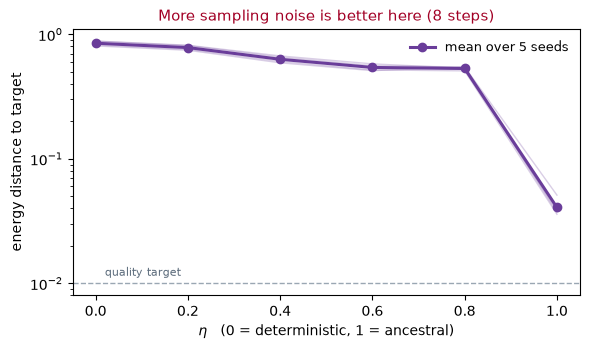

In [35]:
# The eta sweep: one budget, one network, one dial. USE_CACHED = True reads the committed
# results; False recomputes (about one minute on CPU).
USE_CACHED_ETA = True

ETAS      = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
ETA_STEPS = 8

if USE_CACHED_ETA:
    eta_sweep = load_csv_with_provenance(DATA / "toy_eta_sweep.csv", "toy_eta_sweep.csv")
else:
    rows = []
    for eta in ETAS:
        for seed in SEEDS:
            ref = sample_target(N_EVAL, seed=1000 + seed)
            s = ddim_sample(ddpm_net, N_EVAL, steps=ETA_STEPS, seed=seed, eta=eta).numpy()
            rows.append(dict(eta=eta, steps=ETA_STEPS, seed=seed, energy_distance=energy_distance(s, ref)))
    eta_sweep = pd.DataFrame(rows)

eta_mean = eta_sweep.groupby("eta").energy_distance.mean()
print(f"mean energy distance at a fixed {ETA_STEPS}-step budget, 5 seeds\n")
for e, v in eta_mean.items():
    print(f"  eta = {e:.1f}   {v:.5f}")
print(f"\nremoving the sampling noise entirely (eta 1.0 -> 0.0) costs "
      f"{eta_mean.loc[0.0] / eta_mean.loc[1.0]:.1f}x in energy distance")
print(f"monotone decreasing in eta: {bool((eta_mean.diff().dropna() < 0).all())}")

fig, ax = plt.subplots(figsize=(6, 3.6))
for seed, grp in eta_sweep.groupby("seed"):
    g = grp.sort_values("eta")
    ax.plot(g.eta, g.energy_distance, color="#6A3D9A", alpha=0.25, lw=1)
ax.plot(eta_mean.index, eta_mean.values, "o-", color="#6A3D9A", lw=2.2, label="mean over 5 seeds")
ax.axhline(BAND, ls="--", lw=1, color="#9aa7b3")
ax.text(0.02, BAND * 1.15, "quality target", fontsize=8, color="#5B6B7B")
ax.set_yscale("log"); ax.set_xlabel(r"$\eta$   (0 = deterministic, 1 = ancestral)")
ax.set_ylabel("energy distance to target")
ax.set_title(f"More sampling noise is better here ({ETA_STEPS} steps)", color="#A20025", fontsize=11)
ax.legend(frameon=False, fontsize=9); fig.tight_layout(); plt.show()

The curve falls monotonically as `eta` rises. Reading the ends of it: at a fixed 8-step budget,
`eta=0` scores 0.84861 and `eta=1` scores 0.04072, so **removing the sampling noise costs a factor
of 20.8**. Stochasticity is not flattering flow matching. It is propping up the diffusion baseline,
and the published comparison was therefore using the *stronger* of the two available diffusion
samplers, not the weaker one.

That settles the decomposition arithmetic. The sampling-noise component of flow matching's
advantage is **zero or negative**: subtracting it does not shrink the gap, it widens it. Every bit
of the fourfold step saving sits in the other bucket, path geometry and the score accuracy along
that path, and 4x is a **lower bound** on that bucket rather than an estimate of it. Once both
samplers are deterministic the gap is at least 25x in steps and 85x in energy at eight steps.

Why should noise *help*? The intuition worth carrying is that the injected noise acts as a
**stochastic corrector**. Picture the reverse process as walking downhill in fog toward a narrow
ridge, the data manifold, with a compass that is slightly miscalibrated. Every step you take on a
bad bearing carries you a little off the ridge. The deterministic sampler commits fully to each
bearing, so its errors accumulate along the walk; there is no mechanism that ever pulls it back.
The stochastic sampler adds a random jitter at each step, and the denoiser's next call then pulls
whatever it lands on back toward the ridge. Because the network was trained on *noisy* inputs at
every level, it is at its most reliable when handed a point that looks noisy in the way it expects.
The jitter keeps the walk inside the distribution the network knows how to correct.

The measurement below makes that concrete, and adds a second effect specific to this ladder. Both
update rules are affine in the network's output, so you can read their coefficients directly and
see how each one handles the network's error at the noisiest step.

In [38]:
# Where does the deterministic path lose it? Both updates are affine in (x, eps), so their
# coefficients are readable straight off the schedule; then watch the sample spread evolve.
idx8, ab8, abp8 = respace(8)
alpha8 = ab8 / abp8

print("the noisiest step of the 8-step ladder (t = %d):" % int(idx8[-1]))
print(f"  DDIM forms x0 by dividing by sqrt(alpha_bar), amplifying the eps error {1/ab8[-1].sqrt():>8.0f}x")
print(f"  the ancestral update divides by sqrt(alpha) instead, amplifying it    {1/alpha8[-1].sqrt():>8.0f}x")
print(f"  so the deterministic step is {float((1/ab8[-1].sqrt())/(1/alpha8[-1].sqrt())):.1f}x more exposed to the same error\n")

def rms_trace(sampler, **kw):
    """RMS radius of the cloud after each reverse step. A correct sample has RMS near 1."""
    _, traj = sampler(ddpm_net, 2000, steps=8, seed=0, record=True, **kw)
    return [float(s.pow(2).mean().sqrt()) for s in traj[1:]]

anc, det = rms_trace(ddpm_sample), rms_trace(ddim_sample, eta=0.0)
print("  t      rms after ancestral step      rms after DDIM(eta=0) step")
for t, a, d in zip([int(v) for v in reversed(idx8.tolist())], anc, det):
    print(f"{t:4d}   {a:>24.3f}   {d:>26.3f}")
print(f"\ntarget rms = {float(np.sqrt((sample_target(20000, seed=7) ** 2).mean())):.3f}: "
      f"the ancestral walk returns to it, the deterministic one stalls at {det[-1]:.2f}")

# Does clipping the runaway x0 prediction fix it? (This is the x0clip arm in the sweep.)
print(f"\n8-step mean energy, DDIM eta=0 unclipped: {mean_energy.loc['ddim_eta0', 8]:.5f}")
print(f"8-step mean energy, DDIM eta=0 with x0 clipped to +/-4: {mean_energy.loc['ddim_eta0_x0clip', 8]:.5f}"
      f"   ({mean_energy.loc['ddim_eta0', 8] / mean_energy.loc['ddim_eta0_x0clip', 8]:.1f}x better)")
c_clip, c_fm = crossing("ddim_eta0_x0clip"), crossing("fm_euler")
if c_clip and c_fm:
    print(f"and its crossing budget moves from never to {c_clip} steps, "
          f"still {c_clip // c_fm}x flow matching's {c_fm}")

the noisiest step of the 8-step ladder (t = 199):
  DDIM forms x0 by dividing by sqrt(alpha_bar), amplifying the eps error     4058x
  the ancestral update divides by sqrt(alpha) instead, amplifying it         878x
  so the deterministic step is 4.6x more exposed to the same error

  t      rms after ancestral step      rms after DDIM(eta=0) step
 199                     20.852                       20.594
 171                     12.146                        7.987
 142                      2.754                        6.143
 114                      1.736                        4.977
  85                      1.361                        4.088
  57                      1.137                        3.151
  28                      1.056                        2.122
   0                      1.056                        2.071

target rms = 1.001: the ancestral walk returns to it, the deterministic one stalls at 2.07

8-step mean energy, DDIM eta=0 unclipped: 0.84861
8-step mean energy, 

The two columns tell the story cleanly. Both samplers leave the noisiest step in the same bad
place, with an RMS radius above 20 where the data has radius 1.0, because both inherit the same
amplified error there. What happens next is where they part. The ancestral walk is back to 2.75 one
step later and settles at 1.06, the target's own radius. The deterministic path drifts down far more
slowly and **stalls at 2.07**, twice the radius it should have, and a cloud with the wrong spread is
exactly what a large energy distance measures.

Underneath that is a conditioning defect specific to this ladder, and it is a good lesson in reading
your own schedule. The terminal $\bar\alpha$ here is $6.07\times10^{-8}$, because the cosine betas
are clamped at 0.999. DDIM's first move is to divide by $\sqrt{\bar\alpha_t}$, which multiplies
whatever error the network made by **4058**; the ancestral update divides by $\sqrt{\alpha_t}$
instead and amplifies the same error only 878-fold, 4.6 times less exposed. The result is a
predicted "clean point" that lands in the thousands on data whose support stops at 1.9.

That diagnosis is testable, and the clipping arm tests it. Clamp the runaway $\hat{x}_0$ to
$\pm4$, a standard stabiliser and the only change, and the 8-step energy falls from 0.84861 to
0.05953, a **14.3x** improvement, with the crossing budget moving from *never* to **64 steps**.
Most of deterministic DDIM's deficit on this ladder was that conditioning defect rather than
anything about path curvature. And note where the fixed version lands: 64 steps against flow
matching's 8, still an eightfold gap. Repairing the deterministic sampler as well as it can be
repaired does not recover the four-fold claim; it leaves flow matching further ahead than the
original comparison did.

### <b> <font color='#A20025'> What this does and does not license you to say</font> </b>

Now the honest part, because the result is easy to over-read.

This is a **2-D toy** with a **74,882-parameter MLP** and a target you can draw on a napkin. The
finding that deterministic DDIM trails ancestral sampling **here** must not be carried into a claim
about DDIM at production scale. In real image and molecule models DDIM and its higher-order
descendants are the standard few-step samplers precisely because they work well, and the terminal
$\bar\alpha$ that wrecks the deterministic path on our ladder is an artifact of clamping the cosine
betas at 0.999 in a 200-level schedule. Change the schedule and the conditioning defect changes with
it. Read this section as a worked example of how to decompose a claim, not as a benchmark of DDIM.

What the measurement *does* license is a narrower statement than the chapter's original one, and a
stronger one:

> The fourfold step advantage survives holding the sampler family fixed. Flow matching crosses the
> quality band at 8 steps against ancestral diffusion's 32, and making the diffusion sampler
> deterministic widens that gap rather than closing it. The advantage is therefore attributable to
> path geometry, not to a mismatch between a stochastic sampler and an ODE.

That is a claim a reviewer can check, because the arms are matched and the numbers come from a
committed CSV rather than a remembered run. It is also the version worth carrying into the molecular
notebooks, where step budgets translate directly into GPU hours and the same question, is this the
method or is this the sampler, comes up every time.

All of that is summarised in one figure, the chapter's thesis figure, now redrawn with the third
arm in place. It is worth studying before moving on, because it is the visual form of the entire
decomposition: two curves would let you claim flow matching wins, and it takes the third to tell you
*why*.

![Figure I.4]({{artifact:612383a5-90a2-42e0-8e71-52ae7f4c592b}})

**Figure I.4.** The step-count comparison, run as a controlled three-way experiment. Panel (a) plots
energy distance to the two-moons target against the sampling-step budget for three samplers, with
ribbons showing the spread across five seeds and the dashed line marking the 0.01 quality band; the
flow matcher (crimson) crosses that band at 8 steps and the stochastic ancestral diffusion sampler
(grey) at 32, the fourfold saving the chapter claims. The third curve is the control the comparison
needed: DDIM at `eta=0` (purple, dashed) is the deterministic path for the *same* trained diffusion
network on the *same* respaced schedule, and it never reaches the band at all, flattening out at
0.073 once it has used all 200 available noise levels, which is why it carries a "no crossing"
leader instead of a crossing marker. Panel (b) shows the three samplers' 8-step outputs against the
grey target cloud, and the visual ordering matches the metric: the flow-matching moons are clean,
the ancestral moons are ragged but correctly placed, and the deterministic DDIM samples spray off
the manifold entirely. Because the only difference between the two diffusion curves is whether
noise is injected at each step, the figure decomposes the advantage directly: removing the
stochasticity does not shrink flow matching's lead, it widens it, so the fourfold saving is
attributable to path geometry and is a lower bound rather than an estimate. The caveat that keeps
this honest is the scale: a 2-D target and a 74,882-parameter network, so the ranking of diffusion
samplers here should not be read as a general benchmark.

Even at **4 steps** the two moons are clearly there; a budget at which the diffusion sampler in
Notebook 1 produced scattered noise. That is the qualitative version of this chapter's central
claim, and the sweep above is its quantitative version.

One number in the earlier draft of this appendix needs correcting here, and the correction is
instructive. That draft quoted the diffusion model as stranded at **0.371** at eight steps against
flow matching's 0.010, a thirtyfold gap. The 0.371 was real, but it came from a sweep that trained
its diffusion network **inline** rather than loading a checkpoint, and CPU training is not
bit-deterministic. The pinned checkpoint used everywhere in this notebook is a better-converged run
of the same recipe and scores **0.04072** at the same budget, so the matched-budget gap is about
**4x**, not 30x. Both networks are now cached precisely so this class of drift cannot recur, and
every number in this section comes from `data/toy_sampler_sweep.csv`, which those checkpoints
reproduce exactly. The crossing claim, 8 steps against 32, is untouched by the correction; it is the
matched-budget ratio that was inflated.

## <b> <font color='#A20025'> Summary</font> </b>

You built a flow-matching generator on the same two-moons target as Notebook 1, then stress-tested
the comparison itself:

- FM learns a **velocity field** $v_\theta(x,t)$ by regressing onto the conditional velocity $u_t = x_1 - x_0$ along straight source-to-target lines; one plain MSE loss, handled by `torchcfm`.
- **Sampling is ODE integration**: drop a Gaussian sample at $t{=}0$ and follow the field to $t{=}1$ with a few Euler steps.
- The learned paths are **nearly straight**, so a **handful of steps** already yields clean moons; where diffusion needed dozens.
- The step-count claim holds up under a **controlled** three-way sweep. Flow matching crosses the 0.01 quality band at **8** steps, ancestral diffusion at **32**, and deterministic DDIM at no budget within the schedule's 200 noise levels.
- The advantage is therefore **path geometry, not sampler mismatch**. Turning `eta` from 1 down to 0 at a fixed 8-step budget makes the diffusion sampler **20.8x worse**, so the sampling-noise component of flow matching's lead is zero or negative and 4x is a lower bound.
- On this ladder the deterministic path is also **badly conditioned**: a terminal $\bar\alpha$ of $6.07\times10^{-8}$ amplifies the network's error 4058-fold when forming $\hat{x}_0$. Clipping $\hat{x}_0$ recovers most of that (0.849 to 0.060 at 8 steps) and still leaves DDIM crossing at 64.
- Flow matching **generalizes** diffusion (Lipman et al., 2023); you have learned the more flexible tool, and the step-count win is the chapter's thesis, now with its mechanism isolated rather than assumed.

The scope caveat travels with the claim: this is a 2-D toy and a 74,882-parameter network, so the
ranking of diffusion samplers here is a worked example of decomposing a comparison, not a benchmark
of DDIM at scale.

**Next:** we carry this exact idea from a 2-D toy to real molecules; applied de-novo generation with
a pretrained flow-matching model.

### <b> <font color='#A20025'> References</font> </b>

1. Lipman, Chen, Ben-Hamu, Nickel & Le (2023), *Flow Matching for Generative Modeling*, ICLR. arXiv:2210.02747.
2. Tong, Fatras, Malkin, Huguet, Zhang, Rector-Brooks, Wolf & Bengio (2024), *Improving and Generalizing Flow-Based Generative Models with Minibatch Optimal Transport*, TMLR. arXiv:2302.00482. *(the `torchcfm` library)*
3. Liu, Gong & Liu (2023), *Flow Straight and Fast: Learning to Generate and Transfer Data with Rectified Flow*, ICLR. arXiv:2209.03003.
4. Ho, Jain & Abbeel (2020), *Denoising Diffusion Probabilistic Models*, NeurIPS. arXiv:2006.11239. *(the ancestral diffusion baseline from Notebook 1)*
5. Song, Meng & Ermon (2021), *Denoising Diffusion Implicit Models*, ICLR. arXiv:2010.02502. *(DDIM; the deterministic control arm and the `eta` family)*
6. Nichol & Dhariwal (2021), *Improved Denoising Diffusion Probabilistic Models*, ICML. arXiv:2102.09672. *(the cosine schedule whose terminal $\bar\alpha$ drives the conditioning defect)*
7. Karras, Aittala, Aila & Laine (2022), *Elucidating the Design Space of Diffusion-Based Generative Models*, NeurIPS. arXiv:2206.00364. *(stochasticity as an error-correcting mechanism in samplers)*